<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None
quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64
Ratio of classes: quality
5    0.

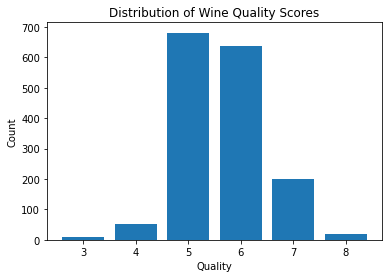

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
#importing wine dataset
data=pd.read_csv(r"C:\Users\mitta\Downloads\wine+quality\winequality-red.csv",delimiter=';')
#inspecting the dataset
print(data.info())
quality_counts=data['quality'].value_counts()
print(quality_counts)
class_ratio=quality_counts/quality_counts.sum()
print(f'Ratio of classes: {class_ratio}')
#vislualising the class imbalances
plt.bar(quality_counts.index,quality_counts.values)
plt.xlabel('Quality')
plt.ylabel('Count')
plt.title('Distribution of Wine Quality Scores')
plt.show()

In [2]:
from sklearn.model_selection import train_test_split
#splitting the dataset into train and test sets
X=data.drop('quality',axis=1)
y=data['quality']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [3]:
#scaling the data
from sklearn.preprocessing import StandardScaler
import numpy as np
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [4]:
#classifier model training
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models={'Random Forest': RandomForestClassifier(random_state=42),
        'K nearest neighbours':KNeighborsClassifier()}
repeatedkf=RepeatedKFold(n_splits=3,n_repeats=10,random_state=42)
for model_name,model in models.items():
    scores=cross_val_score(model,X_train_scaled,y_train,scoring='accuracy',cv=repeatedkf)
    print(f'{model_name}: Mean Accuracy={scores.mean():.2f}, standard deviation={scores.std():.3f}')

Random Forest: Mean Accuracy=0.66, standard deviation=0.022
K nearest neighbours: Mean Accuracy=0.56, standard deviation=0.015


In [5]:
from sklearn.metrics import classification_report
#training the best performing model on the training dataset
model=RandomForestClassifier(random_state=42)
model.fit(X_train_scaled,y_train)
#testing the model with test dataset
predictions=model.predict(X_test_scaled)
print("Classification Report:\n",classification_report(y_test,predictions))

Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.71      0.76      0.73       136
           6       0.64      0.70      0.67       128
           7       0.71      0.55      0.62        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.43      0.39      0.40       320
weighted avg       0.65      0.68      0.66       320



C:\Users\Vishnu\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Vishnu\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Vishnu\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average,

In [6]:
#balancing the scaled training set
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_train_balanced, y_train_balanced=smote.fit_resample(X_train_scaled, y_train)
#inspecting the balanced set and checking ratio of classes
quality_counts=pd.Series(y_train_balanced).value_counts()
print(quality_counts)
class_ratio=quality_counts/quality_counts.sum()
print(f'Ratio of classes: {class_ratio}')

quality
6    545
5    545
7    545
3    545
4    545
8    545
Name: count, dtype: int64
Ratio of classes: quality
6    0.166667
5    0.166667
7    0.166667
3    0.166667
4    0.166667
8    0.166667
Name: count, dtype: float64


In [7]:
#retraining the model on the balanced training set
for model_name,model in models.items():
    scores=cross_val_score(model,X_train_balanced,y_train_balanced,scoring='accuracy',cv=repeatedkf)
    print(f'{model_name}: Mean Accuracy={scores.mean():.2f}, standard deviation={scores.std():.3f}')

Random Forest: Mean Accuracy=0.86, standard deviation=0.012
K nearest neighbours: Mean Accuracy=0.78, standard deviation=0.013


In [8]:
#training the best performing model on the balanced training set
model=RandomForestClassifier(random_state=42)
model.fit(X_train_balanced,y_train_balanced)
#test the best performing model's performance on the test set
predictions=model.predict(X_test_scaled)
print("Classification Report:\n",classification_report(y_test,predictions))

Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.12      0.27      0.17        11
           5       0.73      0.68      0.70       136
           6       0.68      0.60      0.64       128
           7       0.51      0.55      0.53        40
           8       0.11      0.33      0.17         3

    accuracy                           0.61       320
   macro avg       0.36      0.41      0.37       320
weighted avg       0.65      0.61      0.63       320

